# Проверка гипотезы 3. Объём товара (категории)
Кейс 1: «Исследование факторов, влияющих на своевременную доставку и удовлетворённость клиентов». Проект «Влияние на сроки доставки и оценки покупателей маркетплейса Olist».

В этом ноутбуке мы проверяем, связаны ли вес, объём посылки и категория товара с опозданием заказа. Порядок работы: подготовка данных, описательная статистика, графики, взаимосвязи, проверка гипотезы и выводы.

Над гипотезой работали:
- Нерода Дарья
- Чащина Алина

## Что проверяем

**Что говорит заказчик (Иоанн):**
- Главное для бизнеса — своевременная доставка: заказ получен не позже обещанной даты. Быстрая доставка сама по себе не цель.
- Для сравнения достаточно календарных дат фактической и обещанной доставки.
- Решения о том, какие записи и периоды исключать, — наша методическая часть. Мы принимаем их сами, записываем в ноутбуке и обсуждаем с ментором.

**Целевой показатель:** доля опоздавших заказов. Заказ опоздал, если дата получения позже обещанной даты.

**Единица наблюдения:** один доставленный заказ (одна строка = один заказ).

**Гипотезы:**
- **3.1.** Чем больше вес и объём посылки, тем выше доля опоздавших заказов.
- **3.2.** Доля опоздавших заказов различается между категориями товаров.

**Что опровергнет гипотезу:**
- 3.1: доля опозданий у тяжёлых и крупных заказов не выше, чем у лёгких и небольших, или связь исчезает внутри групп (штат, год).
- 3.2: после поправки на множественные сравнения категории не отличаются друг от друга.

**Рабочий порог значимости для бизнеса:** разницу меньше 2 процентных пунктов (п.п.) считаем практически незначимой. Это наше допущение: заказчик порог не называл.

**Какие данные нужны:** заказы (даты, статус), товары в заказах (цена, доставка), товары (вес, размеры, категория), перевод категорий, а также покупатели и продавцы (штат, нужен только для перепроверки).

Общая таблица «один заказ = одна строка» собирается в ноутбуке 01_preprocessing. Чтобы этот ноутбук запускался сам по себе, нужные признаки собираем здесь же.

## 1. Загрузка данных

CSV-файлы лежат в папке `data/`.

In [1]:
# импорт необходимых библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 4)
pd.set_option('display.max_columns', 30)

In [2]:
# загрузка таблиц (названия в том же формате, что в общем ноутбуке)
DATA_DIR = 'data/'

df_orders        = pd.read_csv(DATA_DIR + 'olist_orders_dataset.csv')
df_order_items   = pd.read_csv(DATA_DIR + 'olist_order_items_dataset.csv')
df_products      = pd.read_csv(DATA_DIR + 'olist_products_dataset.csv')
df_category_name = pd.read_csv(DATA_DIR + 'product_category_name_translation.csv')
df_customers     = pd.read_csv(DATA_DIR + 'olist_customers_dataset.csv')
df_sellers       = pd.read_csv(DATA_DIR + 'olist_sellers_dataset.csv')

tables = {'заказы': df_orders, 'товары в заказах': df_order_items, 'товары': df_products,
          'перевод категорий': df_category_name, 'покупатели': df_customers, 'продавцы': df_sellers}

pd.DataFrame({'Таблица': tables.keys(),
              'Строк': [t.shape[0] for t in tables.values()],
              'Столбцов': [t.shape[1] for t in tables.values()]})

,Таблица,Строк,Столбцов
0,заказы,99441,8
1,товары в заказах,112650,7
2,товары,32951,9
3,перевод категорий,71,2
4,покупатели,99441,5
5,продавцы,3095,4


**Вывод:** загружено 6 таблиц. Для гипотезы 3 главные — заказы, товары в заказах, товары и перевод категорий. Покупатели и продавцы нужны только, чтобы потом перепроверить результат по штатам.

## 2. Выбор доставленных заказов и признак опоздания

In [3]:
# работаем с копией, исходная таблица df_orders остаётся без изменений
orders = df_orders.copy()

# даты записаны как текст - переводим в формат даты
date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

print('Всего заказов:', len(orders))
print()
print(orders['order_status'].value_counts().to_string())

Всего заказов: 99441

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2


In [4]:
# для анализа опозданий нужны заказы, которые доставлены и у которых есть дата доставки
delivered = orders[(orders['order_status'] == 'delivered') &
                   (orders['order_delivered_customer_date'].notna())].copy()
print('Доставленных заказов с датой доставки:', len(delivered))

# опоздание: дата получения позже обещанной даты (сравниваем календарные даты, как просил заказчик)
delivered['is_late'] = (delivered['order_delivered_customer_date'].dt.normalize() >
                        delivered['order_estimated_delivery_date'].dt.normalize()).astype(int)

print('Опоздало заказов:', delivered['is_late'].sum())
print('Доля опозданий, %:', round(delivered['is_late'].mean() * 100, 2))

Доставленных заказов с датой доставки: 96470
Опоздало заказов: 6534
Доля опозданий, %: 6.77


**Вывод:** для анализа остаются 96 470 доставленных заказов. Заказы без доставки (отменённые, в пути и др.) не берём: опоздание для них посчитать нельзя. Опоздала примерно каждая пятнадцатая посылка.

## 3. Соединение товаров в заказах с карточками товаров

(проверяем число строк до и после)

In [5]:
print('Строк в таблице товаров в заказах:', len(df_order_items))
print('product_id уникален в таблице товаров:', df_products['product_id'].is_unique)
print('Название категории уникально в переводе:', df_category_name['product_category_name'].is_unique)
print()

# присоединяем карточки товаров (связь N:1, строки размножаться не должны)
items = df_order_items.merge(df_products, how='left', on='product_id')
print('После присоединения товаров:', len(items))

# присоединяем перевод названий категорий
items = items.merge(df_category_name, how='left', on='product_category_name')
print('После присоединения перевода категорий:', len(items))

assert len(items) == len(df_order_items), 'строки размножились!'

Строк в таблице товаров в заказах: 112650
product_id уникален в таблице товаров: True
Название категории уникально в переводе: True

После присоединения товаров: 112650
После присоединения перевода категорий: 112650


**Вывод:** число строк не изменилось (112 650), значит, соединение корректное: одна строка по-прежнему означает один товар в заказе.

## 4. Пропуски и странные значения в весе, размерах и категориях

In [6]:
print('Товаров без категории:', df_products['product_category_name'].isna().sum())
print('Товаров без веса и размеров:', df_products['product_weight_g'].isna().sum())
print('Товаров с весом 0 г:', (df_products['product_weight_g'] == 0).sum())

no_translation = set(df_products['product_category_name'].dropna()) - set(df_category_name['product_category_name'])
print('Категории без перевода:', no_translation)
print()
print('Строк-товаров без категории:', items['product_category_name'].isna().sum(), 'из', len(items))

Товаров без категории: 610
Товаров без веса и размеров: 2
Товаров с весом 0 г: 4
Категории без перевода: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}

Строк-товаров без категории: 1603 из 112650


**Вывод:** есть небольшие проблемы:
- у 610 товаров нет категории;
- у 2 товаров нет веса и размеров;
- у 4 товаров вес равен 0 г, это невозможно;
- у двух категорий нет перевода на английский.

**Что решили (и почему):**
- Вес 0 г считаем пропуском, так как посылка не может ничего не весить. Исходный столбец не меняем, создаём новый.
- Если у товара в заказе нет веса или размеров, общий вес и объём заказа не считаем (иначе они занизятся). Таких заказов очень мало.
- Товары без категории помечаем `unknown` и не удаляем, но в сравнении категорий не используем.
- Категориям без перевода оставляем португальское название.

## 5. Свод данных до уровня заказа

(одна строка = один заказ)

In [7]:
# новые столбцы (исходные не трогаем)
items['weight_g'] = items['product_weight_g'].replace(0, np.nan)
items['volume_cm3'] = items['product_length_cm'] * items['product_height_cm'] * items['product_width_cm']
items['category'] = items['product_category_name_english'].fillna(items['product_category_name']).fillna('unknown')

# считаем показатели на уровне заказа
order_features = items.groupby('order_id').agg(
    n_items=('order_item_id', 'count'),
    weight_sum=('weight_g', 'sum'),
    weight_known=('weight_g', 'count'),
    volume_sum=('volume_cm3', 'sum'),
    volume_known=('volume_cm3', 'count'),
    price_total=('price', 'sum'),
    freight_total=('freight_value', 'sum'),
    n_categories=('category', 'nunique'),
    n_sellers=('seller_id', 'nunique')
).reset_index()

# если у какого-то товара нет веса или размеров, общий вес и объём заказа считать нельзя
order_features.loc[order_features['weight_known'] < order_features['n_items'], 'weight_sum'] = np.nan
order_features.loc[order_features['volume_known'] < order_features['n_items'], 'volume_sum'] = np.nan

# основная категория и продавец заказа - по самому дорогому товару
main_item = (items.sort_values(['order_id', 'price'], ascending=[True, False])
                  .drop_duplicates('order_id')[['order_id', 'category', 'seller_id']]
                  .rename(columns={'category': 'main_category', 'seller_id': 'main_seller_id'}))

print('Заказов в таблице признаков:', len(order_features))
print('Заказов с несколькими категориями, %:', round((order_features['n_categories'] > 1).mean() * 100, 2))
print('Заказов с несколькими продавцами, %:', round((order_features['n_sellers'] > 1).mean() * 100, 2))

Заказов в таблице признаков: 98666
Заказов с несколькими категориями, %: 0.8
Заказов с несколькими продавцами, %: 1.3


In [8]:
# присоединяем признаки к доставленным заказам
data = (delivered.merge(order_features, how='left', on='order_id')
                 .merge(main_item, how='left', on='order_id')
                 .merge(df_customers[['customer_id', 'customer_state']], how='left', on='customer_id')
                 .merge(df_sellers[['seller_id', 'seller_state']], how='left',
                        left_on='main_seller_id', right_on='seller_id')
                 .drop(columns='seller_id'))

print('Строк до объединения:', len(delivered), '| после:', len(data))
print('order_id уникален:', data['order_id'].is_unique)
assert len(data) == len(delivered)

# новые признаки
data['weight_kg'] = data['weight_sum'] / 1000      # вес заказа, кг
data['volume_l'] = data['volume_sum'] / 1000       # объём заказа, литры
data['same_state'] = (data['customer_state'] == data['seller_state']).astype(int)
data['promised_days'] = (data['order_estimated_delivery_date'] - data['order_purchase_timestamp']).dt.total_seconds() / 86400
data['delivery_days'] = (data['order_delivered_customer_date'] - data['order_purchase_timestamp']).dt.total_seconds() / 86400
data['purchase_year'] = data['order_purchase_timestamp'].dt.year

print()
print('Заказов без веса:', data['weight_kg'].isna().sum(), '| без объёма:', data['volume_l'].isna().sum())

Строк до объединения: 96470 | после: 96470
order_id уникален: True

Заказов без веса: 22 | без объёма: 16


**Вывод:** после объединения число строк не изменилось (96 470), каждый заказ встречается один раз. Мы создали признаки: опоздание, вес заказа (кг), объём заказа (литры), число товаров, основная категория, доставка внутри штата, обещанный и фактический срок. Заказов без веса совсем мало, их из анализа веса исключаем.

## 6. Основные показатели веса, объёма, числа товаров, цены и стоимости доставки

In [9]:
data[['weight_kg', 'volume_l', 'n_items', 'price_total', 'freight_total']].describe(percentiles=[.5, .9, .99]).round(2)

,weight_kg,volume_l,n_items,price_total,freight_total
count,96448.00,96454.00,96470.00,96470.00,96470.00
mean,2.39,17.33,1.14,137.04,22.79
std,4.77,30.14,0.54,209.05,21.56
min,0.00,0.17,1.00,0.85,0.00
50%,0.75,7.25,1.00,86.50,17.17
90%,6.55,42.98,1.00,269.00,39.38
99%,22.35,135.69,3.00,990.00,104.25
max,184.40,1476.00,21.00,13440.00,1794.96


**Вывод:** типичный заказ лёгкий и небольшой: половина заказов весит меньше 0,75 кг, 90% меньше 6,5 кг. Но есть очень тяжёлые заказы (максимум 184 кг), поэтому распределение сильно «скошено». Большинство заказов состоит из одного товара. Для графиков и сравнений используем группы, а не средние значения.

## 7. Распределения веса и объёма

(по 99-му перцентилю обрезаем хвост, чтобы график был читаемым)

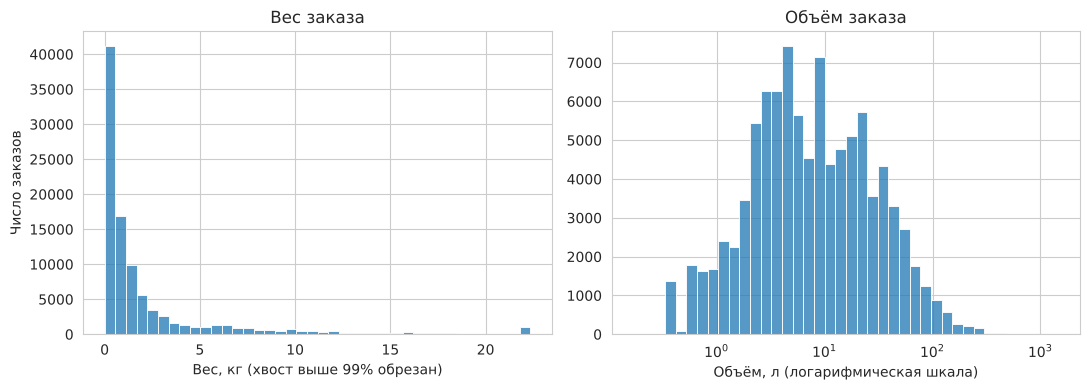

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

w = data['weight_kg'].dropna()
sns.histplot(w.clip(upper=w.quantile(0.99)), bins=40, ax=ax[0])
ax[0].set_title('Вес заказа')
ax[0].set_xlabel('Вес, кг (хвост выше 99% обрезан)')
ax[0].set_ylabel('Число заказов')

sns.histplot(data['volume_l'].dropna(), bins=40, log_scale=True, ax=ax[1])
ax[1].set_title('Объём заказа')
ax[1].set_xlabel('Объём, л (логарифмическая шкала)')
ax[1].set_ylabel('')

plt.tight_layout()
plt.show()

**Вывод:** основная масса заказов — лёгкие и небольшие, длинный «хвост» тяжёлых заказов небольшой. Поэтому тяжёлые заказы выделим в отдельную группу.

## 8. Как сравниваем группы

Чтобы сравнить группы, посчитаем долю опозданий в каждой и добавим 95% доверительный интервал (ДИ): диапазон, в котором, скорее всего, находится истинная доля. Чем меньше заказов в группе, тем шире интервал.

In [11]:
def wilson(k, n, z=1.96):
    # 95% доверительный интервал для доли (метод Уилсона)
    p = k / n
    den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half

def late_by_group(df, group):
    # доля опозданий по группам
    t = df.groupby(group, observed=True)['is_late'].agg(['size', 'sum'])
    t.columns = ['заказов', 'опоздало']
    t['доля опозданий, %'] = t['опоздало'] / t['заказов'] * 100
    ci = [wilson(k, n) for k, n in zip(t['опоздало'], t['заказов'])]
    t['ДИ от, %'] = [c[0] * 100 for c in ci]
    t['ДИ до, %'] = [c[1] * 100 for c in ci]
    return t

def plot_late(t, title, xlabel):
    # столбцы - доля опозданий, чёрные линии - доверительный интервал, пунктир - общая доля
    fig, ax = plt.subplots()
    x = range(len(t))
    ax.bar(x, t['доля опозданий, %'], color='tab:blue', alpha=0.8)
    err = [t['доля опозданий, %'] - t['ДИ от, %'], t['ДИ до, %'] - t['доля опозданий, %']]
    ax.errorbar(x, t['доля опозданий, %'], yerr=err, fmt='none', ecolor='black', capsize=4)
    ax.axhline(data['is_late'].mean() * 100, color='red', linestyle='--', label='все заказы')
    for i, (v, top) in enumerate(zip(t['доля опозданий, %'], t['ДИ до, %'])):
        ax.text(i, top + 0.2, f'{v:.1f}'.replace('.', ',') + '%', ha='center', fontsize=9)
    ax.set_ylim(0, t['ДИ до, %'].max() + 1.5)
    ax.set_xticks(list(x))
    ax.set_xticklabels(t.index)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Доля опоздавших заказов, %')
    ax.legend()
    plt.tight_layout()
    plt.show()

## 9. Доля опозданий по весу заказа

,заказов,опоздало,"доля опозданий, %","ДИ от, %","ДИ до, %"
weight_group,,,,,
"до 0,5",38823,2534,6.53,6.29,6.78
"0,5-1",16895,1066,6.31,5.95,6.69
1-2,16406,1133,6.91,6.53,7.30
2-5,11332,789,6.96,6.51,7.45
5-10,7724,545,7.06,6.51,7.65
более 10,5268,467,8.86,8.13,9.66


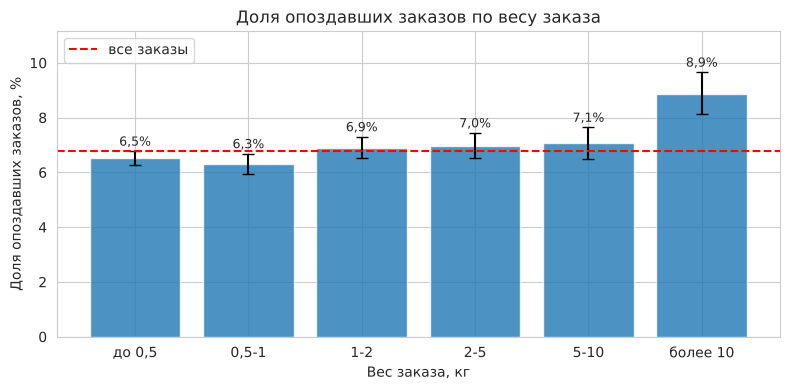

In [12]:
w_bins = [0, 0.5, 1, 2, 5, 10, np.inf]
w_labels = ['до 0,5', '0,5-1', '1-2', '2-5', '5-10', 'более 10']
data['weight_group'] = pd.cut(data['weight_kg'], bins=w_bins, labels=w_labels, include_lowest=True)

t_weight = late_by_group(data, 'weight_group')
display(t_weight.round(2))
plot_late(t_weight, 'Доля опоздавших заказов по весу заказа', 'Вес заказа, кг')

**Вывод:** до 5 кг доля опозданий почти не меняется (6,3-7,0%). Заметно выше она только у самых тяжёлых заказов: более 10 кг. Доверительные интервалы у групп «до 0,5 кг» и «более 10 кг» не пересекаются.

## 10. Доля опозданий по объёму заказа

(5 групп с одинаковым числом заказов)

,заказов,опоздало,"доля опозданий, %","ДИ от, %","ДИ до, %"
volume_group,,,,,
"0,2-2,5",19471,1215,6.24,5.91,6.59
"2,5-4,8",19123,1385,7.24,6.88,7.62
"4,8-10,3",19294,1180,6.12,5.79,6.46
"10,3-24,3",19278,1362,7.07,6.71,7.44
"24,3-1476,0",19288,1392,7.22,6.86,7.59


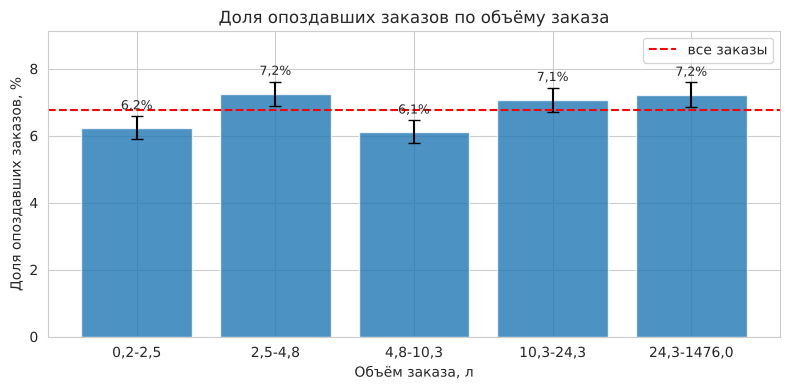

In [13]:
edges = data['volume_l'].quantile([0, .2, .4, .6, .8, 1]).round(1).tolist()
v_labels = [f'{edges[i]}-{edges[i + 1]}'.replace('.', ',') for i in range(5)]
data['volume_group'] = pd.qcut(data['volume_l'], 5, labels=v_labels)

t_volume = late_by_group(data, 'volume_group')
display(t_volume.round(2))
plot_late(t_volume, 'Доля опоздавших заказов по объёму заказа', 'Объём заказа, л')

**Вывод:** у объёма ровного роста нет: доля опозданий прыгает вверх и вниз (6,1-7,2%) и не растёт от маленьких заказов к большим. Разница между группами небольшая.

## 11. Доля опозданий по числу товаров в заказе

,заказов,опоздало,"доля опозданий, %","ДИ от, %","ДИ до, %"
items_group,,,,,
1,86835,6024,6.94,6.77,7.11
2,7392,397,5.37,4.88,5.91
3 и больше,2243,113,5.04,4.21,6.02


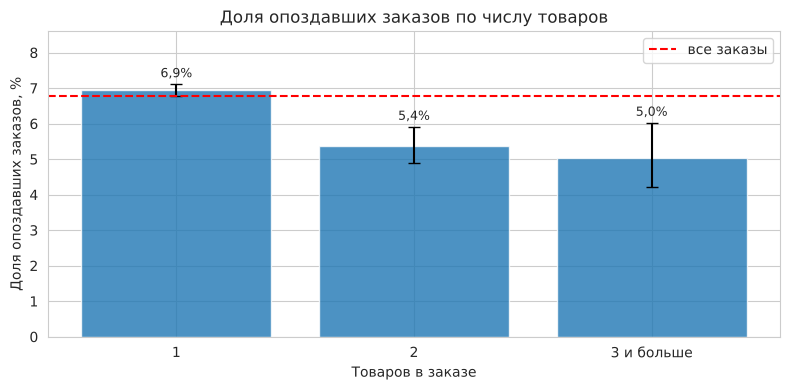

In [14]:
data['items_group'] = data['n_items'].clip(upper=3).map({1: '1', 2: '2', 3: '3 и больше'})
t_items = late_by_group(data, 'items_group')
display(t_items.round(2))
plot_late(t_items, 'Доля опоздавших заказов по числу товаров', 'Товаров в заказе')

**Вывод:** заказы из нескольких товаров опаздывают реже, чем из одного, хотя они тяжелее. Это неожиданно, и по данным причину мы определить не можем.

## 12. Доля опозданий по категориям товаров

Берём основную категорию заказа (по самому дорогому товару). Для сравнения оставляем категории, где не меньше 300 заказов, иначе доли получаются случайными. Категорию `unknown` не сравниваем: это не настоящая категория.

In [15]:
cat_counts = data['main_category'].value_counts()
big_cats = [c for c in cat_counts[cat_counts >= 300].index if c != 'unknown']
print('Всего категорий:', len(cat_counts) - 1)
print('Категорий с 300 и более заказов:', len(big_cats))
print('Доля заказов в этих категориях, %:', round(data['main_category'].isin(big_cats).mean() * 100, 1))

Всего категорий: 73
Категорий с 300 и более заказов: 31
Доля заказов в этих категориях, %: 93.6


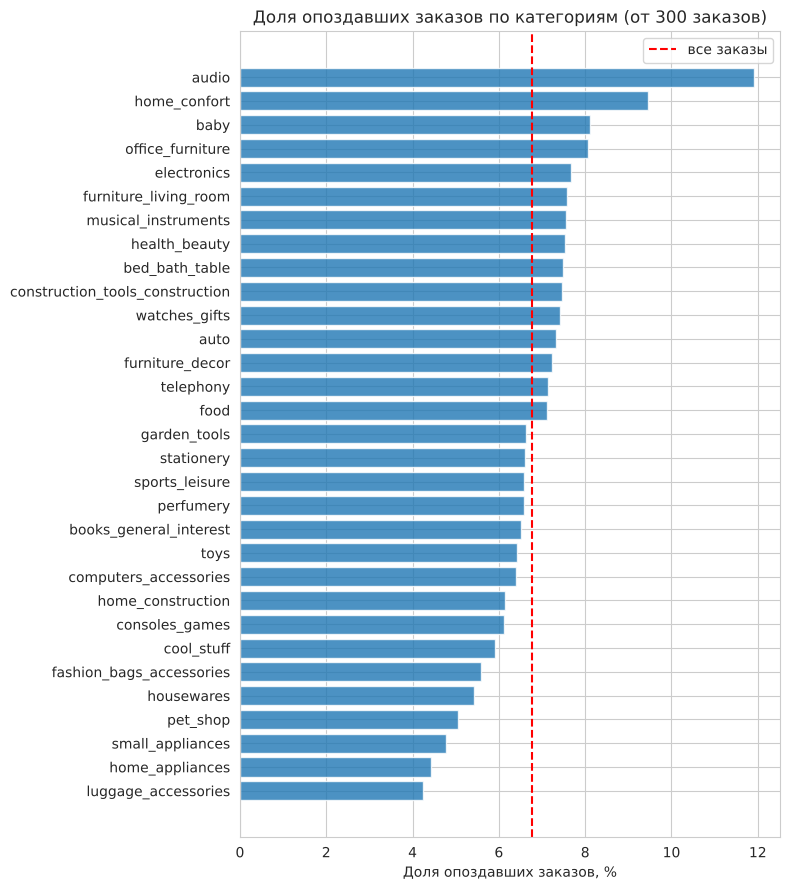

In [16]:
cat_table = (data[data['main_category'].isin(big_cats)].groupby('main_category')['is_late']
             .agg(['size', 'mean']).rename(columns={'size': 'заказов', 'mean': 'доля опозданий'}))
cat_table['доля опозданий'] = cat_table['доля опозданий'] * 100
cat_table = cat_table.sort_values('доля опозданий')

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(cat_table.index, cat_table['доля опозданий'], color='tab:blue', alpha=0.8)
ax.axvline(data['is_late'].mean() * 100, color='red', linestyle='--', label='все заказы')
ax.set_title('Доля опоздавших заказов по категориям (от 300 заказов)')
ax.set_xlabel('Доля опоздавших заказов, %')
ax.legend()
plt.tight_layout()
plt.show()

**Вывод:** доля опозданий в категориях заметно отличается: от 4,3% (`luggage_accessories`) до 11,9% (`audio`). Но среди них есть небольшие категории, поэтому нужно проверить, не случайны ли различия (см. раздел E).

## 13. Корреляции между опозданием, весом, объёмом, стоимостью доставки и сроками

(корреляция Спирмена)

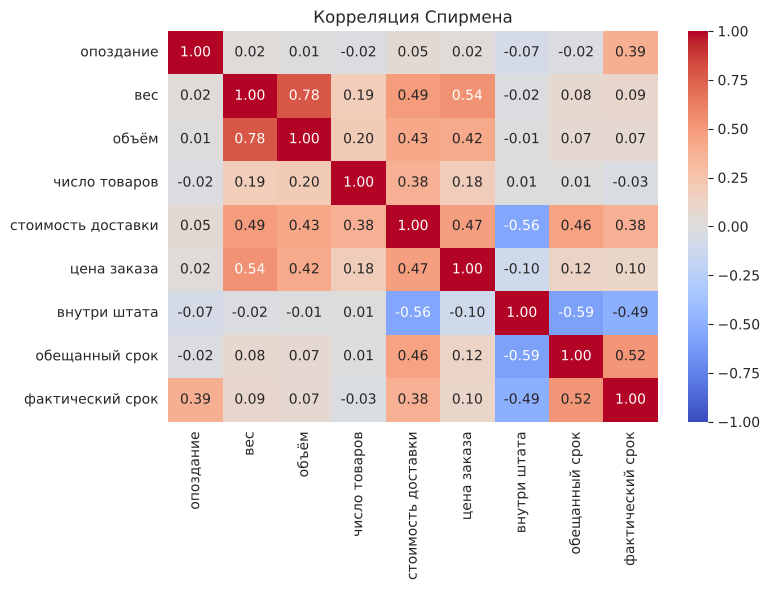

In [17]:
corr_cols = {'is_late': 'опоздание', 'weight_kg': 'вес', 'volume_l': 'объём', 'n_items': 'число товаров',
             'freight_total': 'стоимость доставки', 'price_total': 'цена заказа', 'same_state': 'внутри штата',
             'promised_days': 'обещанный срок', 'delivery_days': 'фактический срок'}
corr = data[list(corr_cols)].rename(columns=corr_cols).corr(method='spearman')

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Корреляция Спирмена')
plt.tight_layout()
plt.show()

**Вывод:**
- Связь опоздания с весом (0,02) и объёмом (0,01) очень слабая. Корреляция показывает среднюю связь по всем заказам, а у нас эффект проявляется в основном у тяжёлых заказов.
- Вес и объём связаны между собой (чем тяжелее, тем обычно больше).
- Стоимость доставки заметно связана с весом, а ещё сильнее — с тем, внутри штата доставка или нет. Значит, она отчасти показывает расстояние (это тема гипотезы 1).

## 14. Стоимость доставки: это вес или расстояние?

Смотрим долю опозданий по стоимости доставки отдельно для доставки внутри штата и в другой штат.

In [18]:
data['freight_group'] = pd.qcut(data['freight_total'], 5, labels=['1 (дешёвая)', '2', '3', '4', '5 (дорогая)'])
freight_table = data.pivot_table(index='freight_group', columns='same_state', values='is_late',
                                 aggfunc='mean', observed=True) * 100
freight_table.columns = ['в другой штат, %', 'внутри штата, %']
print('Корреляция Спирмена стоимости доставки с весом:', round(stats.spearmanr(data['freight_total'], data['weight_kg'], nan_policy='omit')[0], 2))
freight_table.round(2)

Корреляция Спирмена стоимости доставки с весом: 0.49


,"в другой штат, %","внутри штата, %"
freight_group,,
1 (дешёвая),5.53,4.36
2,7.22,4.22
3,8.05,4.92
4,8.26,4.69
5 (дорогая),8.57,5.59


**Вывод:** внутри одного штата доля опозданий по стоимости доставки меняется слабо (4,2-5,6%), а при доставке в другой штат сильнее (5,5-8,6%). Значит, стоимость доставки в основном отражает расстояние и относится к гипотезе 1. Мы используем её как контрольную переменную, а не как отдельный фактор гипотезы 3.

## 15. Обещанный и фактический срок по весу заказа

In [19]:
days_table = data.groupby('weight_group', observed=True)[['promised_days', 'delivery_days']].mean().round(1)
days_table['запас, дней'] = (days_table['promised_days'] - days_table['delivery_days']).round(1)
days_table.columns = ['обещанный срок, дней', 'фактический срок, дней', 'запас, дней']
days_table

,"обещанный срок, дней","фактический срок, дней","запас, дней"
weight_group,,,
"до 0,5",23.0,12.0,11.0
"0,5-1",23.8,12.4,11.4
1-2,23.9,12.7,11.2
2-5,24.2,12.9,11.3
5-10,24.9,13.5,11.4
более 10,25.9,14.9,11.0


**Вывод:** с ростом веса растут и обещанный, и фактический сроки (примерно с 23 до 26 и с 12 до 15 дней), а запас остаётся почти одинаковым (около 11 дней). Значит, площадка уже закладывает больше времени на тяжёлые заказы, но для самых тяжёлых этого запаса не хватает.

## 16. Гипотеза 3.1: связь веса и объёма с опозданием

Используем три простых проверки:
- хи-квадрат: отличается ли доля опозданий между группами;
- критерий Манна-Уитни: отличается ли вес заказа у опоздавших и доставленных вовремя;
- корреляция Спирмена: есть ли общая связь.

In [20]:
def test_numeric(col, group):
    d = data.dropna(subset=[col])
    chi2, p_chi, _, _ = stats.chi2_contingency(pd.crosstab(d[group], d['is_late']))
    late = d.loc[d['is_late'] == 1, col]
    ontime = d.loc[d['is_late'] == 0, col]
    p_mw = stats.mannwhitneyu(late, ontime).pvalue
    rho, p_rho = stats.spearmanr(d[col], d['is_late'])
    return pd.Series({'p хи-квадрат (группы)': p_chi, 'p Манна-Уитни': p_mw,
                      'корреляция Спирмена': rho, 'p корреляции': p_rho,
                      'медиана у опоздавших': late.median(), 'медиана вовремя': ontime.median()})

tests = pd.DataFrame({'вес, кг': test_numeric('weight_kg', 'weight_group'),
                      'объём, л': test_numeric('volume_l', 'volume_group')})
tests.round(4)

,"вес, кг","объём, л"
p хи-квадрат (группы),0.0000,0.0000
p Манна-Уитни,0.0000,0.0026
корреляция Спирмена,0.0165,0.0097
p корреляции,0.0000,0.0026
медиана у опоздавших,0.8170,7.6290
медиана вовремя,0.7500,7.2000


**Вывод:** p-значения очень маленькие (меньше 0,05), то есть различия между группами не случайны. Но мы знаем, что в данных почти 100 тысяч заказов, и при таком объёме значимым становится даже небольшое различие. Поэтому смотрим не только на p-значение, но и на размер разницы.

## 17. Размер разницы: самые тяжёлые заказы против самых лёгких

In [21]:
light = data[data['weight_group'] == 'до 0,5']['is_late']
heavy = data[data['weight_group'] == 'более 10']['is_late']

diff = (heavy.mean() - light.mean()) * 100
se = np.sqrt(light.mean() * (1 - light.mean()) / len(light) + heavy.mean() * (1 - heavy.mean()) / len(heavy)) * 100

print('Доля опозданий у заказов до 0,5 кг, %:', round(light.mean() * 100, 2), '| заказов:', len(light))
print('Доля опозданий у заказов более 10 кг, %:', round(heavy.mean() * 100, 2), '| заказов:', len(heavy))
print('Разница, п.п.:', round(diff, 2), '| 95% ДИ:', round(diff - 1.96 * se, 2), '-', round(diff + 1.96 * se, 2))

# для сравнения: самая лёгкая и самая тяжёлая пятая часть заказов по весу
q = pd.qcut(data['weight_kg'], 5, labels=False)
rates = data.groupby(q)['is_late'].mean() * 100
print('Разница между пятой и первой пятой частью по весу, п.п.:', round(rates.iloc[-1] - rates.iloc[0], 2))

Доля опозданий у заказов до 0,5 кг, %: 6.53 | заказов: 38823
Доля опозданий у заказов более 10 кг, %: 8.86 | заказов: 5268
Разница, п.п.: 2.34 | 95% ДИ: 1.53 - 3.14
Разница между пятой и первой пятой частью по весу, п.п.: 1.46


**Вывод:** у заказов тяжелее 10 кг доля опозданий выше на 2,3 п.п. (интервал 1,5-3,1 п.п.), то есть выше нашего рабочего порога 2 п.п. Но если сравнивать пятую часть самых тяжёлых и самых лёгких заказов, разница всего 1,5 п.п. Значит, эффект веса есть, но он небольшой и связан в основном с очень тяжёлыми заказами. Для объёма разница между группами не растёт с размером.

## 18. Гипотеза 3.2: различия между категориями

Сравниваем каждую категорию со всеми остальными заказами. Так как категорий много (31), вероятность случайно найти «особенную» категорию высока. Поэтому используем поправку Бонферрони: p-значение умножаем на число сравнений.

In [22]:
big = data[data['main_category'].isin(big_cats)]
chi2, p_all, _, _ = stats.chi2_contingency(pd.crosstab(big['main_category'], big['is_late']))
print('Различаются ли категории в целом (хи-квадрат), p =', p_all)

rows = []
for c in big_cats:
    a = data[data['main_category'] == c]
    b = data[data['main_category'] != c]
    tab = [[a['is_late'].sum(), len(a) - a['is_late'].sum()], [b['is_late'].sum(), len(b) - b['is_late'].sum()]]
    rows.append({'категория': c, 'заказов': len(a), 'доля опозданий, %': a['is_late'].mean() * 100,
                 'медианный вес, кг': a['weight_kg'].median(), 'p': stats.chi2_contingency(tab)[1]})

cat_tests = pd.DataFrame(rows).sort_values('доля опозданий, %').reset_index(drop=True)
cat_tests['p с поправкой'] = (cat_tests['p'] * len(cat_tests)).clip(upper=1)

print('Категорий, которые отличаются после поправки (p < 0,05):', (cat_tests['p с поправкой'] < 0.05).sum())
display(cat_tests[cat_tests['p с поправкой'] < 0.05].round(4))

Различаются ли категории в целом (хи-квадрат), p = 1.1182784095022323e-11
Категорий, которые отличаются после поправки (p < 0,05): 2


,категория,заказов,"доля опозданий, %","медианный вес, кг",p,p с поправкой
4,housewares,5680,5.4225,1.45,0.0000,0.0010
30,audio,344,11.9186,0.40,0.0002,0.0068


**Вывод:** в целом категории различаются (p очень маленькое). Но после поправки на множественные сравнения отличаются только две категории: `housewares` (реже опаздывает, 5,4%) и `audio` (чаще, 11,9%, но заказов всего 344). Остальные различия могут быть случайными.

## 19. Объясняется ли разница между категориями размером товара?

Сравним медианный вес категории и её долю опозданий.

Корреляция Спирмена (медианный вес категории и доля опозданий): 0.1 | p = 0.58


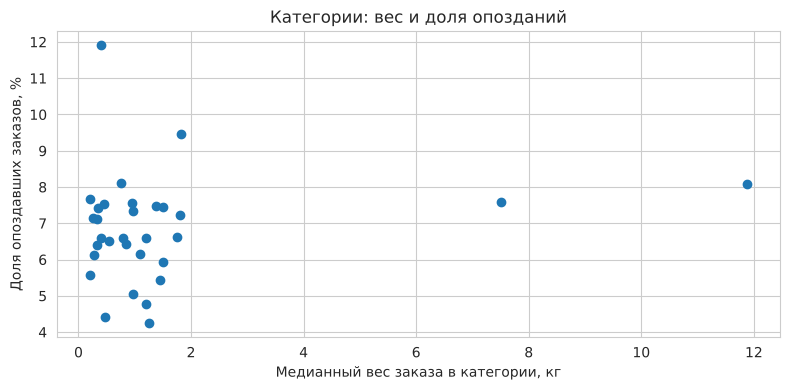

In [23]:
rho_cat, p_cat = stats.spearmanr(cat_tests['медианный вес, кг'], cat_tests['доля опозданий, %'])
print('Корреляция Спирмена (медианный вес категории и доля опозданий):', round(rho_cat, 2), '| p =', round(p_cat, 2))

plt.figure()
plt.scatter(cat_tests['медианный вес, кг'], cat_tests['доля опозданий, %'])
plt.xlabel('Медианный вес заказа в категории, кг')
plt.ylabel('Доля опоздавших заказов, %')
plt.title('Категории: вес и доля опозданий')
plt.tight_layout()
plt.show()

**Вывод:** связи нет: тяжёлые категории не опаздывают чаще лёгких. Значит, различия между категориями связаны с чем-то другим, а не с размером товара (например, с продавцами или регионами; это нужно проверять отдельно).

## 20. Перепроверка: сохраняется ли эффект веса в разных частях данных

Смотрим разницу «более 10 кг» и «до 0,5 кг» при разных вариантах расчёта.

In [24]:
def check(dd):
    g = dd.groupby('weight_group', observed=True)['is_late'].mean() * 100
    return pd.Series({'заказов': len(dd), 'до 0,5 кг, %': g.iloc[0], 'более 10 кг, %': g.iloc[-1],
                      'разница, п.п.': g.iloc[-1] - g.iloc[0]})

variants = {
    'все доставленные заказы': data,
    'без краёв периода (01.2017-08.2018)': data[(data['order_purchase_timestamp'] >= '2017-01-01') &
                                                (data['order_purchase_timestamp'] < '2018-09-01')],
    'доставка внутри штата': data[data['same_state'] == 1],
    'доставка в другой штат': data[data['same_state'] == 0],
    'заказы 2017 года': data[data['purchase_year'] == 2017],
    'заказы 2018 года': data[data['purchase_year'] == 2018],
}
robust = pd.DataFrame({name: check(dd) for name, dd in variants.items()}).T
robust['заказов'] = robust['заказов'].astype(int)
robust.round(2)

,заказов,"до 0,5 кг, %","более 10 кг, %","разница, п.п."
все доставленные заказы,96470,6.53,8.86,2.34
без краёв периода (01.2017-08.2018),96203,6.54,8.89,2.35
доставка внутри штата,34690,4.14,6.78,2.64
доставка в другой штат,61780,7.95,10.13,2.18
заказы 2017 года,43426,4.86,8.29,3.43
заказы 2018 года,52777,7.78,9.43,1.65


**Вывод:**
- Эффект веса сохраняется и внутри штата, и при доставке в другой штат. Значит, он не объясняется только расстоянием.
- Если убрать края периода с очень малым числом заказов, результат не меняется. Поэтому пока оставляем все доставленные заказы (решение согласуем с ментором).
- В 2017 году разница больше (3,4 п.п.), в 2018 году меньше (1,7 п.п.). Эффект нестабилен во времени, это нужно учитывать в выводах.

## 21. Перепроверка по группам веса внутри штата и между штатами

In [25]:
seg = data.pivot_table(index='weight_group', columns='same_state', values='is_late', aggfunc='mean', observed=True) * 100
seg.columns = ['в другой штат, %', 'внутри штата, %']
display(seg.round(2))

for s, name in [(0, 'в другой штат'), (1, 'внутри штата')]:
    d = data[data['same_state'] == s]
    p = stats.chi2_contingency(pd.crosstab(d['weight_group'], d['is_late']))[1]
    print(f'Доставка {name}: различие между группами веса, p =', round(p, 5))

,"в другой штат, %","внутри штата, %"
weight_group,,
"до 0,5",7.95,4.14
"0,5-1",7.48,4.14
1-2,7.94,4.98
2-5,8.31,4.43
5-10,8.24,4.73
более 10,10.13,6.78


Доставка в другой штат: различие между группами веса, p = 0.00011
Доставка внутри штата: различие между группами веса, p = 0.0


**Вывод:** в обоих случаях доля опозданий растёт с весом (внутри штата с 4,1% до 6,8%, в другой штат с 8,0% до 10,1%), различия между группами значимы. Общий вывод по весу не меняется при разбиении на сегменты.

## 22. Что мы поняли (выводы по гипотезе 3)

**Таблица выводов** (отдельно: что видим, возможное объяснение, что это значит для гипотезы, ограничения)

| № | Наблюдение | Возможное объяснение | Для гипотезы | Ограничения |
|---|---|---|---|---|
| 1 | Вес: доля опозданий 6,5% (до 0,5 кг) и 8,9% (более 10 кг). До 5 кг почти не меняется | Тяжёлые посылки сложнее хранить, упаковывать и перевозить | 3.1 подтверждается частично: только для очень тяжёлых заказов | Эффект небольшой (на границе порога 2 п.п.); вес указывают продавцы в карточке товара |
| 2 | Объём: доля опозданий не растёт с размером (6,1-7,2%) | Объём коробки сам по себе мало влияет на срок | 3.1 для объёма не подтверждается | Объём считаем по габаритам из карточки товара |
| 3 | Заказы из нескольких товаров опаздывают реже (5,4% и ниже против 6,9%) | По данным определить нельзя | Не противоречит, но показывает: «больше товаров» не значит «чаще опоздание» | Таких заказов около 10% |
| 4 | Категории: от 4,3% до 11,9%, но после поправки отличаются только `housewares` и `audio` | Возможно, дело в продавцах или регионах, а не в самих товарах | 3.2 подтверждается слабо | У `audio` всего 344 заказа; 1% заказов имеет несколько категорий |
| 5 | Размер категории (медианный вес) не связан с её долей опозданий | Различия категорий не из-за размера | Разница категорий не объясняется объёмом и весом | Категорий мало (31) |
| 6 | Эффект веса есть внутри штата и между штатами; в 2017 году сильнее (3,4 п.п.), в 2018 слабее (1,7 п.п.) | Возможно, изменились логистика или нагрузка | Эффект нестабилен во времени | Нужны дополнительные данные по перевозчикам |
| 7 | Обещанный срок растёт с весом почти так же, как фактический | Площадка уже закладывает больше времени на тяжёлые заказы | Запаса для >10 кг не хватает | Обещанный срок мог зависеть от расстояния, а не только веса |

**Итог по гипотезе 3: подтверждается частично.**
- 3.1: доля опозданий выше только у очень тяжёлых заказов (более 10 кг, это около 5% заказов). Для объёма связи нет.
- 3.2: категории различаются, но надёжно только две, и размер товара эти различия не объясняет.

**Уточнённая формулировка гипотезы после EDA:** заказы тяжелее 10 кг опаздывают чаще лёгких на 2-3 п.п.; объём заказа и размер категории сами по себе опозданий не объясняют.

**Предварительные рекомендации для заказчика:**
- проверить, хватает ли запаса в обещанной дате для заказов тяжелее 10 кг, и при необходимости увеличить этот запас;
- отдельно посмотреть заказы в категориях `audio` и `housewares`, а также продавцов в этих категориях.

**Что передаём в следующий этап (апробация, регрессия):**
- включить вес (или признак «заказ тяжелее 10 кг»), доставку внутри штата, стоимость доставки и месяц покупки;
- проверить, остаётся ли эффект веса при учёте расстояния (гипотеза 1) и продавца (гипотеза 2).

**Что уточнить у ментора:**
- можно ли оставить все доставленные заказы, не исключая края периода (результат от этого не меняется);
- достаточно ли порога 2 п.п. как практической значимости;
- как поступать с заказами из нескольких категорий (мы берём категорию самого дорогого товара).